In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
# 1. Veriyi oku
df = pd.read_csv("all_data_ratio.csv", encoding='utf-8-sig')

In [20]:
# 2. İngilizce etiketli kolonları hazırla
etiketler = {
    'yıl': 'year',
    'uzman': 'specialist',
    'pratisyen': 'practitioner',
    'asistan': 'resident',
    'diger': 'other',
    'ebe': 'midwife',
    'hemsire': 'nurse',
    'hastane': 'hospital',
    'yatak': 'bed',
    'nufus': 'population'
}

# Burada df kullanmalısın, df_temel değil
df_temel_english = df.rename(columns=etiketler)

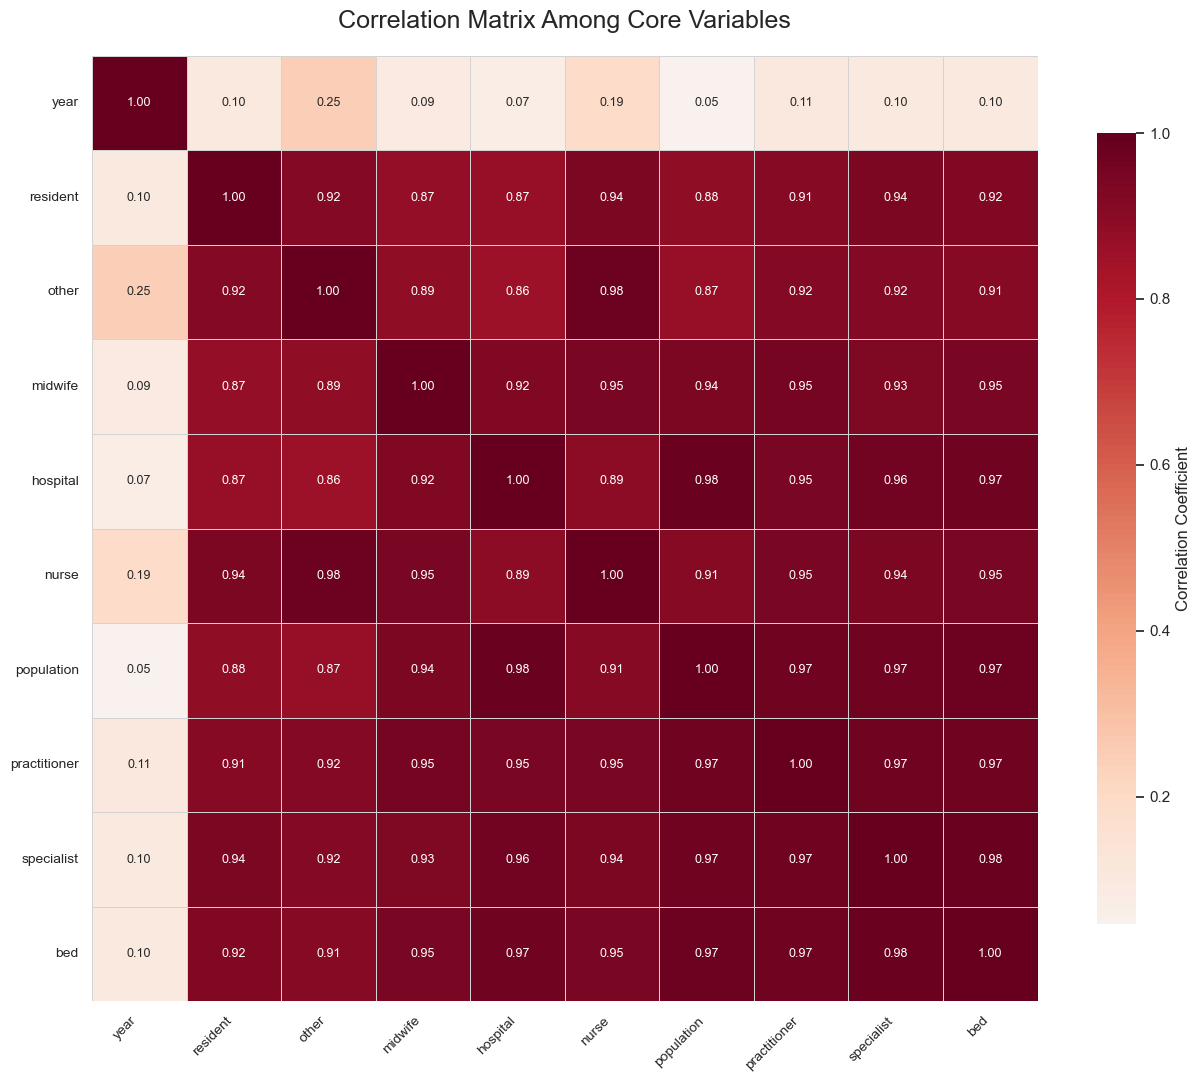

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sadece sayısal sütunları al
df_numerics = df_temel_english.select_dtypes(include=['number'])

# İstenmeyen sütunları çıkart
sutunlar_haric = ['toplam_saglikci', 'doktor_toplami', 'bakim_personeli_toplami', 'disci', 'eczaci']
df_numerics = df_numerics.drop(columns=[s for s in sutunlar_haric if s in df_numerics.columns])

# Korelasyon matrisi
corr = df_numerics.corr()

# Grafik boyutu ve stil ayarları
plt.figure(figsize=(13, 11))
sns.set(style="white")

# Heatmap çizimi
ax = sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    square=True,
    linewidths=0.6,
    linecolor='lightgray',
    cbar_kws={"shrink": .8, "label": "Correlation Coefficient"},
    annot_kws={"size": 9}
)

# Başlık ve eksen ayarları
ax.set_title("Correlation Matrix Among Core Variables", fontsize=18, pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()


In [30]:
corr.to_csv("temel_ozellikler_korelasyon_matrisi.csv", encoding='utf-8-sig', float_format="%.2f")